# Kernels and margins: from similarities to a boundary

A linear SVM scores an observation with $w^\top x+b$, so its boundary is a
line in a two-feature plot. Here one class occupies an inner ring and the
other an outer ring: no single line can separate them. A **kernel** supplies
similarities $K(x,x')$ that act like inner products in a richer feature space.
The SVM can learn a linear margin there, which appears curved in the
original two-feature plane.

This notebook answers three concrete questions:

1. What numbers does an RBF kernel compute, and what is a Gram matrix?
2. How do fitted support vectors determine a new observation's score?
3. How does the similarity scale $\gamma$ change the boundary and accuracy?

The NumPy fitting algorithm is developed separately in
`numpy-svm-from-scratch.ipynb`. Here we inspect the geometry of a fitted
model. No external data files are needed; run the cells in order.

training rows: 168 test rows: 72
class counts in training: [84 84]


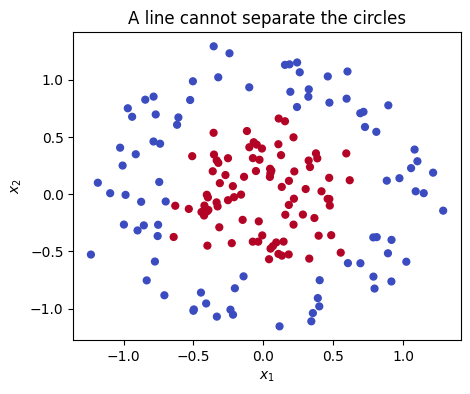

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

SEED = 26509
X, y = make_circles(n_samples=240, factor=.43, noise=.15,
                    random_state=SEED)
# Label 0 is the inner ring; label 1 is the outer ring.
train, test = train_test_split(np.arange(len(y)), test_size=.30,
                               random_state=SEED, stratify=y)
print('training rows:', len(train), 'test rows:', len(test))
print('class counts in training:', np.bincount(y[train]))
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(X[train, 0], X[train, 1], c=y[train], cmap='coolwarm', s=24)
ax.set(xlabel='$x_1$', ylabel='$x_2$', title='A line cannot separate the circles')
plt.show()

## 1. The RBF Gram matrix

For $\gamma>0$, the RBF kernel is

$$K_\gamma(x,x')=\exp\{-\gamma\|x-x'\|_2^2\}.$$

The entry $K_{ij}$ measures similarity between training rows $i$ and $j$.
At zero distance, similarity is one. At distance $d$, it is
$e^{-\gamma d^2}$, so increasing $\gamma$ makes similarity decay faster. A
Gram matrix is the table of all pairwise training similarities. Its
diagonal must be one and it must be symmetric. A valid kernel Gram matrix
is positive semidefinite: every eigenvalue is nonnegative apart from
floating-point roundoff. We check these properties on 60 rows to keep the
heatmap readable. The color of cell $(i,j)$ is $K(x_i,x_j)$, not a class
probability.

Gram shape: (60, 60)
largest symmetry error: 0.0
smallest eigenvalue: 3.51938227062059e-08


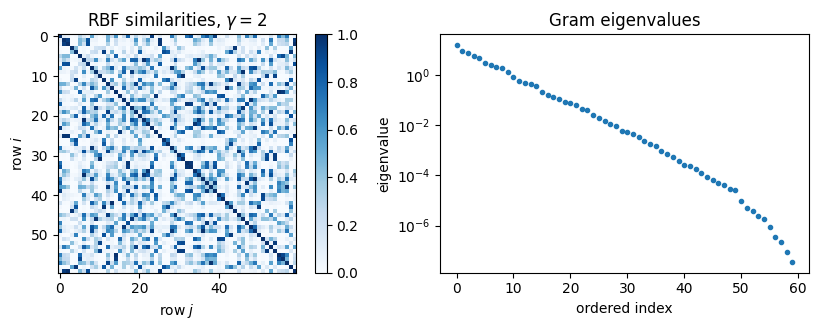

In [2]:
def rbf_kernel(A, B, gamma):
    # A has shape (n, d), B has shape (m, d); output has shape (n, m).
    squared_distance = np.sum((A[:, None, :] - B[None, :, :])**2, axis=2)
    return np.exp(-gamma * squared_distance)

small = X[train[:60]]
K = rbf_kernel(small, small, gamma=2.0)
eigenvalues = np.linalg.eigvalsh(K)
print('Gram shape:', K.shape)
print('largest symmetry error:', np.max(np.abs(K-K.T)))
print('smallest eigenvalue:', eigenvalues.min())
assert np.allclose(np.diag(K), 1)
assert np.allclose(K, K.T)
assert eigenvalues.min() > -1e-10

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
image = axes[0].imshow(K, cmap='Blues', vmin=0, vmax=1)
axes[0].set(title='RBF similarities, $\gamma=2$', xlabel='row $j$', ylabel='row $i$')
fig.colorbar(image, ax=axes[0], fraction=.046)
axes[1].semilogy(np.maximum(eigenvalues[::-1], 1e-15), marker='.', linestyle='none')
axes[1].set(title='Gram eigenvalues', xlabel='ordered index', ylabel='eigenvalue')
plt.tight_layout(); plt.show()

The eigenvalue test checks this particular
matrix; it is not a proof about every possible dataset. The RBF formula is
a valid kernel in general. The heatmap makes the feature-space idea
concrete: we never need to write down $\phi(x)$ itself, only its inner
products $K(x_i,x_j)=\phi(x_i)^\top\phi(x_j)$.

An SVM uses those similarities to fit a score
$f(x)=\sum_i\alpha_i y_i K(x_i,x)+b$. Most $\alpha_i$ are zero; rows with
nonzero coefficients are the **support vectors**. Prediction needs
similarities to those selected rows, rather than the entire training set.

## 2. Reconstruct an SVM score by hand

For the binary SVM, scikit-learn stores coefficients
$c_j=\alpha_j y_j$ for the support vectors. Thus

$$f(x)=\sum_{j\in\mathrm{SV}}c_j K_\gamma(x,x_j)+b.$$

The next cell evaluates this formula with our own kernel function and checks
it against `decision_function`. The matrix multiplication has shape
$(n_{\rm test},n_{\rm SV})$ times $(n_{\rm SV},)$, producing one score per
test row. A positive score predicts class 1; a negative score predicts
class 0. This is the precise sense in which the feature map remains
implicit.

In [3]:
gamma = 2.0
svm = SVC(kernel='rbf', gamma=gamma, C=1.0).fit(X[train], y[train])
manual_score = (rbf_kernel(X[test], svm.support_vectors_, gamma)
                @ svm.dual_coef_.ravel() + svm.intercept_[0])
library_score = svm.decision_function(X[test])
print('number of support vectors:', len(svm.support_))
print('maximum score difference:', np.max(np.abs(manual_score-library_score)))
print('first test row: manual score', round(manual_score[0], 4),
      'library score', round(library_score[0], 4),
      'predicted class', int(manual_score[0] >= 0))
assert np.allclose(manual_score, library_score, atol=1e-10)

number of support vectors: 41
maximum score difference: 1.5543122344752192e-15
first test row: manual score -1.5772 library score -1.5772 predicted class 0


## 3. The RBF scale and the margin tradeoff

Compare a linear SVM with three RBF scales, holding the split and $C$ fixed.
Small $\gamma$ makes similarity broad; large $\gamma$ makes it local. The
solid contour is $f(x)=0$. Dashed contours mark $f(x)=\pm1$, and open circles
mark training support vectors. The table keeps training and test accuracy
separate so the visual flexibility has a measurable consequence.

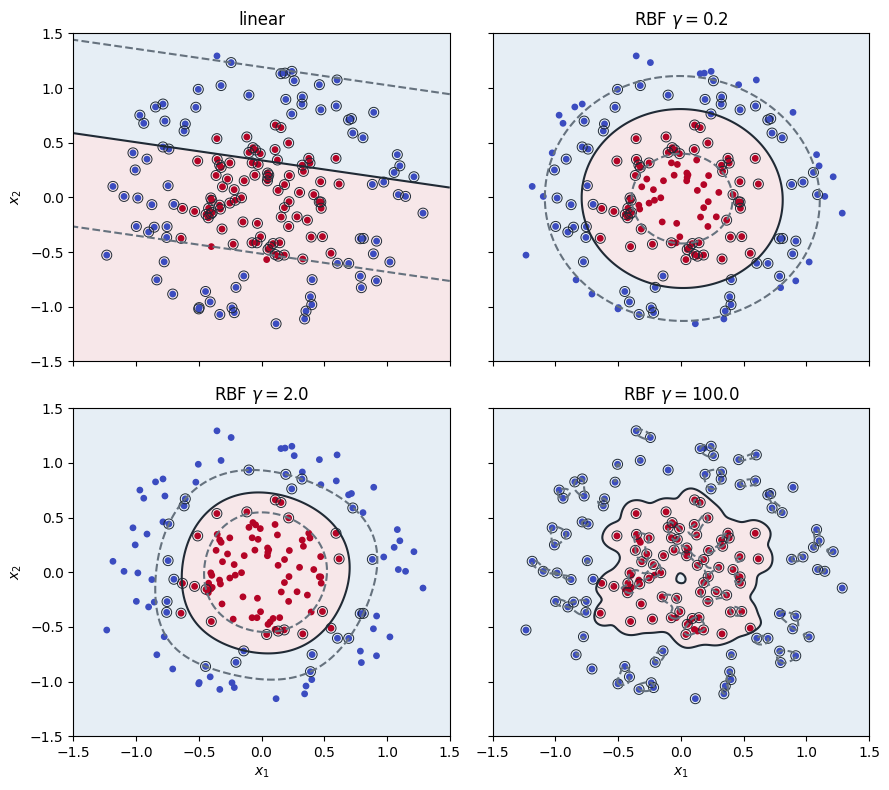

,train accuracy,test accuracy,support vectors
model,,,
linear,0.613,0.597,165
RBF $\gamma=0.2$,0.976,0.944,108
RBF $\gamma=2.0$,0.988,0.958,41
RBF $\gamma=100.0$,1.000,0.931,149


In [4]:
settings = [('linear', None), ('RBF', .2), ('RBF', 2.0), ('RBF', 100.0)]
xx, yy = np.meshgrid(np.linspace(-1.5, 1.5, 240),
                     np.linspace(-1.5, 1.5, 240))
grid = np.column_stack([xx.ravel(), yy.ravel()])
fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True)
rows = []
for ax, (kind, scale) in zip(axes.flat, settings):
    model = SVC(kernel='linear' if scale is None else 'rbf',
                gamma='scale' if scale is None else scale, C=1.0)
    model.fit(X[train], y[train])
    score = model.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, score, levels=[-1e6, 0, 1e6],
                colors=['#DCE8F2', '#F4DEE0'], alpha=.7)
    ax.contour(xx, yy, score, levels=[-1, 0, 1],
               colors=['#66727E', '#202A35', '#66727E'],
               linestyles=['dashed', 'solid', 'dashed'])
    ax.scatter(X[train, 0], X[train, 1], c=y[train], cmap='coolwarm', s=15)
    support = X[train][model.support_]
    ax.scatter(support[:, 0], support[:, 1], s=52,
               facecolors='none', edgecolors='#202A35', linewidth=.7)
    label = 'linear' if scale is None else f'RBF $\gamma={scale}$'
    ax.set(title=label, xlim=(-1.5, 1.5), ylim=(-1.5, 1.5))
    rows.append({'model': label,
                 'train accuracy': model.score(X[train], y[train]),
                 'test accuracy': model.score(X[test], y[test]),
                 'support vectors': len(model.support_)})
for ax in axes[-1]: ax.set_xlabel('$x_1$')
for ax in axes[:, 0]: ax.set_ylabel('$x_2$')
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index('model').round(3))

## What to take away

The kernel does not assign class labels on its own. It supplies inner products
to the margin optimization problem, which selects support vectors and their
coefficients. The same RBF formula can appear in kernel smoothing from
Lecture 6, but that method averages responses rather than optimizing a
classification margin.

## Try it

Before rerunning Section 3, predict what will change when $C$ goes from
$0.1$ to $10$. Compare the number of support vectors and the held-out
accuracy; decide whether the extra flexibility helped on this split.